In [ ]:
from google.colab import files
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
uploaded = files.upload()
file_name = list(uploaded.keys())[0]
df = pd.read_csv(file_name)
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

df.head()

Saving insurance_complete_simulated.csv to insurance_complete_simulated.csv
Rows: 678013
Columns: 16


,IDpol,ClaimNb,Exposure,Area,VehPower,VehAge,DrivAge,BonusMalus,VehBrand,VehGas,Density,Region,Premium,Claim_Amount,Policy_Type,Vehicle_Property_Type
0,1,1,0.10,D,5,0,55,50,B12,Regular,1217,R82,202.51,807.53,Motor Insurance,Medium Power Vehicle
1,3,1,0.77,D,5,0,55,50,B12,Regular,1217,R82,277.29,3042.44,Motor Insurance,Medium Power Vehicle
2,5,1,0.75,B,6,2,52,50,B12,Diesel,54,R22,342.82,681.55,Motor Insurance,Medium Power Vehicle
3,10,1,0.09,B,7,0,46,50,B12,Diesel,76,R72,221.80,378.61,Motor Insurance,Medium Power Vehicle
4,11,1,0.84,B,7,0,46,50,B12,Diesel,76,R72,264.64,3884.15,Motor Insurance,Medium Power Vehicle


In [ ]:

print("Missing Values:")
print(df.isnull().sum())
print("\nDuplicate Rows:", df.duplicated().sum())
df = df.drop_duplicates()
print("\nInvalid Claim Values:", (df["ClaimNb"] < 0).sum())
print("Invalid Exposure Values:", (df["Exposure"] <= 0).sum())
print("Invalid Premium Values:", (df["Premium"] <= 0).sum())
print("Invalid Claim Amounts:", (df["Claim_Amount"] < 0).sum())

Missing Values:
IDpol                    0
ClaimNb                  0
Exposure                 0
Area                     0
VehPower                 0
VehAge                   0
DrivAge                  0
BonusMalus               0
VehBrand                 0
VehGas                   0
Density                  0
Region                   0
Premium                  0
Claim_Amount             0
Policy_Type              0
Vehicle_Property_Type    0
dtype: int64

Duplicate Rows: 0

Invalid Claim Values: 0
Invalid Exposure Values: 0
Invalid Premium Values: 0
Invalid Claim Amounts: 0


In [ ]:

display(df.describe())
print("Total Policies:", len(df))
print("Total Claims:", df["ClaimNb"].sum())
print("Total Claim Amount:", df["Claim_Amount"].sum())
print("Average Premium:", df["Premium"].mean())
print("Average Claim Amount:", df["Claim_Amount"].mean())

,IDpol,ClaimNb,Exposure,VehPower,VehAge,DrivAge,BonusMalus,Density,Premium,Claim_Amount
count,6.780130e+05,678013.000000,678013.000000,678013.000000,678013.000000,678013.000000,678013.000000,678013.000000,678013.000000,678013.000000
mean,2.621857e+06,0.053247,0.528750,6.454631,7.044265,45.499122,59.761502,1792.422405,300.263552,130.599828
std,1.641783e+06,0.240117,0.364442,2.050906,5.666232,14.137444,15.636658,3958.646564,81.872965,723.822438
min,1.000000e+00,0.000000,0.002732,4.000000,0.000000,18.000000,50.000000,1.000000,107.290000,0.000000
25%,1.157951e+06,0.000000,0.180000,5.000000,2.000000,34.000000,50.000000,92.000000,233.580000,0.000000
50%,2.272152e+06,0.000000,0.490000,6.000000,6.000000,44.000000,50.000000,393.000000,294.700000,0.000000
75%,4.046274e+06,0.000000,0.990000,7.000000,11.000000,55.000000,64.000000,1658.000000,357.380000,0.000000
max,6.114330e+06,16.000000,2.010000,15.000000,100.000000,100.000000,230.000000,27000.000000,854.540000,39924.880000


Total Policies: 678013
Total Claims: 36102
Total Claim Amount: 88548381.03999998
Average Premium: 300.2635522327744
Average Claim Amount: 130.59982779091254


In [ ]:

claim_frequency = df["ClaimNb"].sum() / df["Exposure"].sum()
claim_severity = df["Claim_Amount"].sum() / df["ClaimNb"].sum()
print("Claim Frequency:", round(claim_frequency, 4))
print("Claim Severity:", round(claim_severity, 2))

Claim Frequency: 0.1007
Claim Severity: 2452.73


In [ ]:

region_analysis = df.groupby("Region").agg(
    Claims=("ClaimNb", "sum"),
    Claim_Amount=("Claim_Amount", "sum"),
    Exposure=("Exposure", "sum"),
    Premium=("Premium", "mean")
).reset_index()
region_analysis["Claim_Frequency"] = (
    region_analysis["Claims"] /
    region_analysis["Exposure"]
)
region_analysis["Claim_Severity"] = (
    region_analysis["Claim_Amount"] /
    region_analysis["Claims"]
)
display(
    region_analysis.sort_values(
        "Claim_Frequency",
        ascending=False
    )
)

,Region,Claims,Claim_Amount,Exposure,Premium,Claim_Frequency,Claim_Severity
21,R94,247,584041.51,1765.935399,277.693685,0.139869,2364.540526
1,R21,160,362093.49,1205.831509,275.721266,0.132689,2263.084313
0,R11,3978,9868708.14,30208.641954,289.641351,0.131684,2480.821554
2,R22,439,1033645.92,3574.410221,292.803820,0.122817,2354.546515
17,R82,5032,12205591.24,45347.417286,303.580729,0.110966,2425.594444
9,R42,133,338349.13,1209.115823,307.867723,0.109998,2543.978421
20,R93,3907,9659368.16,35790.321015,284.405058,0.109164,2472.323563
16,R74,259,612512.29,2395.994542,294.972275,0.108097,2364.912317
19,R91,1547,3681797.75,14736.104177,278.323318,0.104980,2379.959761
7,R31,1176,2879904.49,11497.974269,287.033762,0.102279,2448.898376


In [ ]:

high_cost = df[df["Claim_Amount"] > df["Claim_Amount"].quantile(0.95)]

print("High-cost policies:", len(high_cost))

display(
    high_cost[
        ["IDpol", "Region", "ClaimNb", "Claim_Amount", "Premium"]
    ].head(10)
)

High-cost policies: 33901


,IDpol,Region,ClaimNb,Claim_Amount,Premium
0,1,R82,1,807.53,202.51
1,3,R82,1,3042.44,277.29
2,5,R22,1,681.55,342.82
3,10,R72,1,378.61,221.80
4,11,R72,1,3884.15,264.64
5,13,R31,1,1116.35,234.58
6,15,R31,1,996.52,265.66
7,17,R91,1,3447.06,255.03
8,18,R91,1,4829.38,355.94
9,21,R52,1,4225.70,188.61


In [ ]:


Q1 = df["Claim_Amount"].quantile(0.25)
Q3 = df["Claim_Amount"].quantile(0.75)
IQR = Q3 - Q1
upper_limit = Q3 + 1.5 * IQR
unusual = df[df["Claim_Amount"] > upper_limit]
print("Unusual Claim Records:", len(unusual))

Unusual Claim Records: 34060


In [ ]:

print(
    "Premium vs Claim Amount Correlation:",
    df["Premium"].corr(df["Claim_Amount"])
)

Premium vs Claim Amount Correlation: 0.06968783220913681


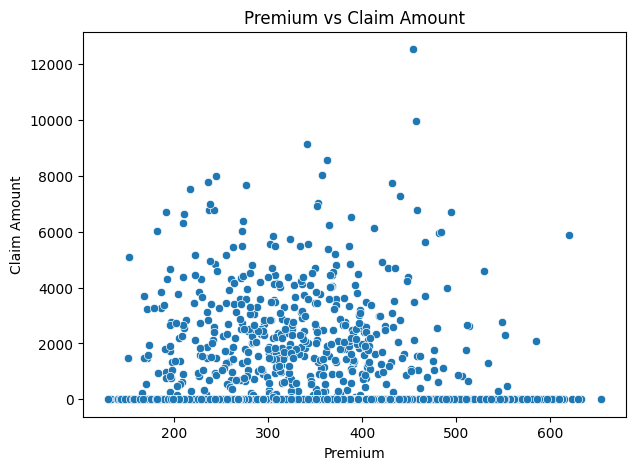

In [ ]:
plt.figure(figsize=(7,5))
sns.scatterplot(
    data=df.sample(10000, random_state=42),
    x="Premium",
    y="Claim_Amount"
)
plt.title("Premium vs Claim Amount")
plt.xlabel("Premium")
plt.ylabel("Claim Amount")
plt.show()

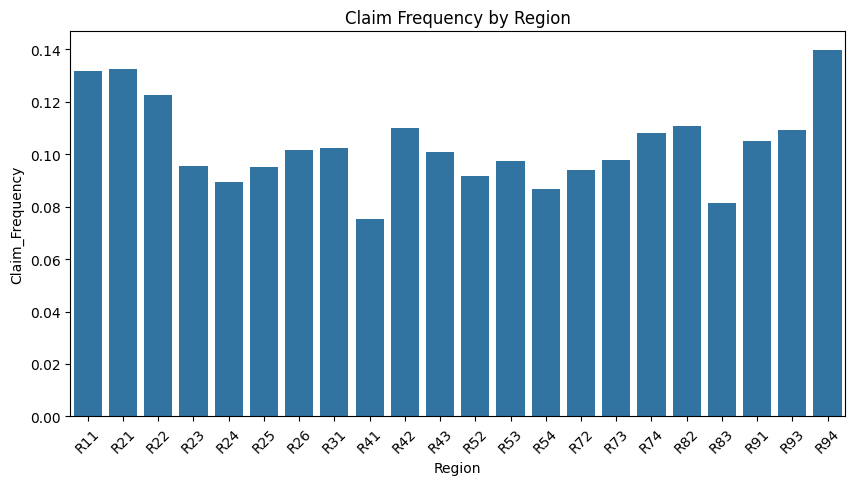

In [ ]:
# 1. Claim Frequency by Region
plt.figure(figsize=(10,5))

sns.barplot(
    data=region_analysis,
    x="Region",
    y="Claim_Frequency"
)
plt.title("Claim Frequency by Region")
plt.xticks(rotation=45)
plt.show()

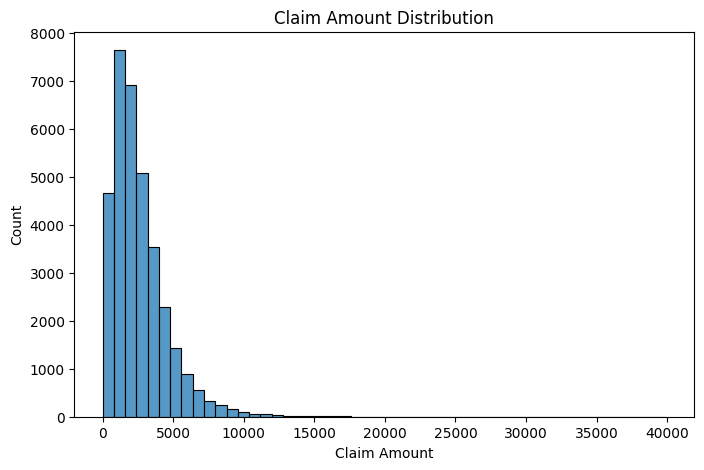

In [ ]:
# 2. Claim Amount Distribution
plt.figure(figsize=(8,5))

sns.histplot(
    df[df["Claim_Amount"] > 0]["Claim_Amount"],
    bins=50
)
plt.title("Claim Amount Distribution")
plt.xlabel("Claim Amount")
plt.show()

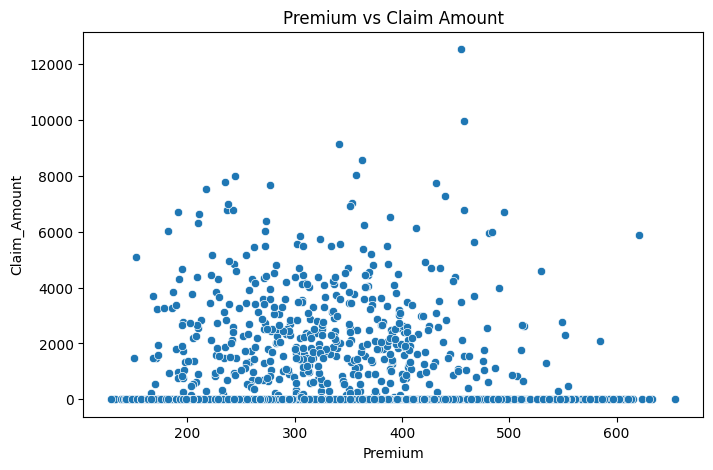

In [ ]:
# 3. Premium vs Claim Amount
plt.figure(figsize=(8,5))
sns.scatterplot(
    data=df.sample(10000, random_state=42),
    x="Premium",
    y="Claim_Amount"
)
plt.title("Premium vs Claim Amount")
plt.show()

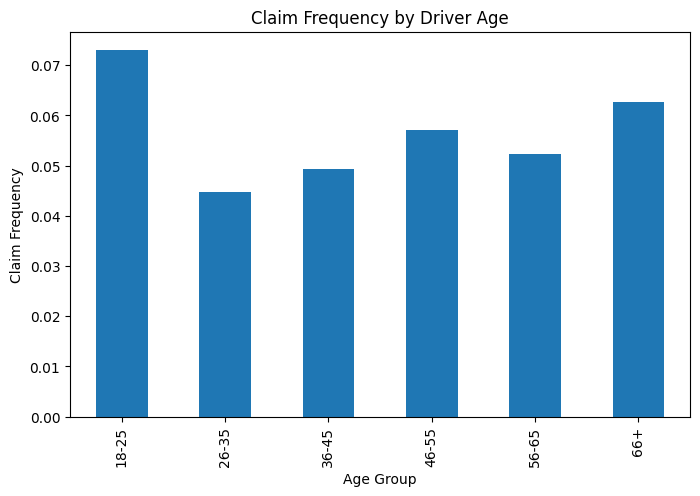

In [ ]:
# 4. Claim Frequency by Driver Age
df["Age_Group"] = pd.cut(
    df["DrivAge"],
    bins=[17,25,35,45,55,65,100],
    labels=["18-25","26-35","36-45","46-55","56-65","66+"]
)
age_claims = df.groupby(
    "Age_Group",
    observed=True
)["ClaimNb"].mean()
age_claims.plot(kind="bar", figsize=(8,5))
plt.title("Claim Frequency by Driver Age")
plt.xlabel("Age Group")
plt.ylabel("Claim Frequency")
plt.show()

In [ ]:

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
df_model = df.sample(
    n=50000,
    random_state=42
)
features = [
    "Premium",
    "DrivAge",
    "VehAge",
    "VehPower",
    "BonusMalus",
    "Density",
    "Exposure"
]
X = df_model[features]
y = df_model["Claim_Amount"]
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)
model = RandomForestRegressor(
    n_estimators=20,
    max_depth=12,
    random_state=42,
    n_jobs=-1
)
model.fit(X_train, y_train)
print("Random Forest Model Trained Successfully!")
print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Random Forest Model Trained Successfully!
Training records: 40000
Testing records: 10000


In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
y_pred = model.predict(X_test)
MAE = mean_absolute_error(y_test, y_pred)
RMSE = np.sqrt(mean_squared_error(y_test, y_pred))
R2 = r2_score(y_test, y_pred)
print("MAE :", round(MAE, 2))
print("RMSE:", round(RMSE, 2))
print("R²  :", round(R2, 4))

MAE : 240.76
RMSE: 712.64
R²  : -0.0289


In [ ]:
importance = pd.DataFrame({
    "Feature": features,
    "Importance": model.feature_importances_
}).sort_values(
    "Importance",
    ascending=False
)
display(importance)

,Feature,Importance
0,Premium,0.291535
5,Density,0.207334
1,DrivAge,0.130579
6,Exposure,0.107748
2,VehAge,0.094048
4,BonusMalus,0.087289
3,VehPower,0.081467


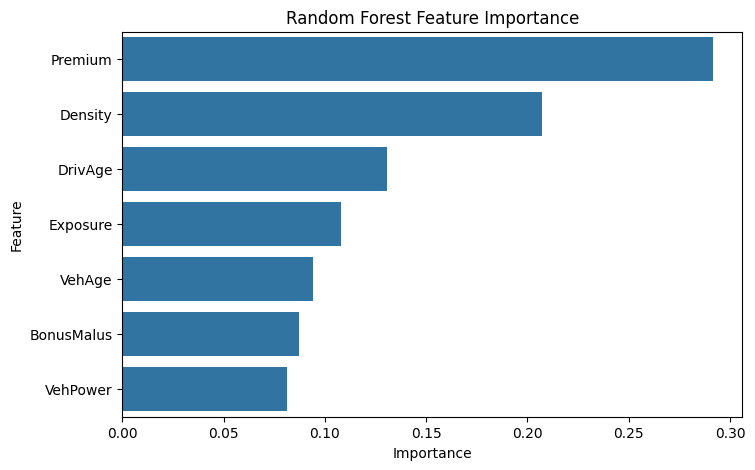

In [ ]:
plt.figure(figsize=(8,5))
sns.barplot(
    data=importance,
    x="Importance",
    y="Feature"
)
plt.title("Random Forest Feature Importance")
plt.show()